In [1]:
# Customer Review Sentiment Analysis using NLP and LSTM

print("Customer Review Sentiment Analysis Project")
print("Using NLP, RNN and LSTM")

Customer Review Sentiment Analysis Project
Using NLP, RNN and LSTM


### Task 1 – Text Data Preparation

- Load, clean, preprocess, and prepare the text dataset for model training.

* Perform the following tasks:
  - Text cleaning
  - Tokenization
  - Stopword removal
  - Stemming / Lemmatization (optional)
  - Word indexing
  - Sequence generation
  - Padding sequences
  - Train-test splitting

In [2]:
from tensorflow.keras.datasets import imdb

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=10000)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Training samples: 25000
Testing samples: 25000


In [3]:
import numpy as np
import pandas as pd

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nFirst review:")
print(X_train[0])

print("\nFirst sentiment:")
print(y_train[0])

print("\nUnique labels:")
print(np.unique(y_train))

Training data shape: (25000,)
Testing data shape: (25000,)

First review:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345,

In [4]:
# Load IMDB word index
word_index = imdb.get_word_index()

# Reverse the word index
reverse_word_index = {
    value: key for key, value in word_index.items()
}

# Function to decode review
def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(i - 3, "?")
        for i in encoded_review
        if i >= 4
    )

# Decode first training review
sample_review = decode_review(X_train[0])

print("Original Review:")
print(sample_review)

print("\nSentiment:", y_train[0])

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Original Review:
this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy's that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and sho

In [5]:
print("Negative Review:")
print(decode_review(X_train[np.where(y_train == 0)[0][0]]))

print("\nPositive Review:")
print(decode_review(X_train[np.where(y_train == 1)[0][0]]))

Negative Review:
big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is completely laughable the best is the end showdown with the cop and how he worked out who the killer is it's just so damn terribly written the clothes are sickening and funny in equal the hair is big lots of boobs men wear those cut shirts that show off their sickening that men actually wore them and the music is just trash that plays over and over again in almost every scene there is trashy music boobs and taking away bodies and the gym still doesn't close for all joking aside this is a truly bad film whose only charm is to look back on the disaster that was the 80's and have a good old laugh at how bad everything was back then

Positive Review:
this film was just brilliant casting lo

In [6]:
import re

def clean_text(text):

    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Remove URLs
    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [11]:
# Decode the first review again

word_index = imdb.get_word_index()

reverse_word_index = {
    value: key for key, value in word_index.items()
}

decoded_review = " ".join(
    reverse_word_index.get(i - 3, "?")
    for i in X_train[0]
)

print("Original Review:")
print(decoded_review)

Original Review:
? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have d

In [12]:
cleaned_positive = clean_text(decoded_review)

negative_review = """
big hair big boobs bad music and a giant safety pin
these are the words to best describe this terrible movie
"""

cleaned_negative = clean_text(negative_review)

print("Cleaned Positive Review:")
print(cleaned_positive)

print("\nCleaned Negative Review:")
print(cleaned_negative)

Cleaned Positive Review:
this film was just brilliant casting location scenery story direction everyone s really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also to the two little boy s that played the of norman and paul they were just brilliant children are often left out of the list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should be praised for what they have done do

In [13]:
print("Original length:", len(decoded_review))
print("Cleaned length:", len(cleaned_positive))

print("\nCleaning completed successfully!")

Original length: 1113
Cleaned length: 1099

Cleaning completed successfully!


In [14]:
!pip install nltk

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 13.3 MB/s  0:00:00

   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ---------------------------------------- 0/3 [tqdm]
   ------------- -------------------------- 1/3 [regex]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- ------------- 2/3 [nltk]
   -------------------------- 

In [15]:
import nltk

nltk.download('stopwords')

from nltk.corpus import stopwords

stop_words = set(stopwords.words('english'))

# Preserve important negation words
stop_words = stop_words - {'not', 'no', 'nor'}

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [16]:
def remove_stopwords(text):
    words = text.split()

    filtered_words = [
        word for word in words
        if word not in stop_words
    ]

    return " ".join(filtered_words)

In [17]:
positive_without_stopwords = remove_stopwords(cleaned_positive)

negative_without_stopwords = remove_stopwords(cleaned_negative)

print("Positive Review After Stopword Removal:")
print(positive_without_stopwords)

print("\nNegative Review After Stopword Removal:")
print(negative_without_stopwords)

Positive Review After Stopword Removal:
film brilliant casting location scenery story direction everyone really suited part played could imagine robert amazing actor director father came scottish island loved fact real connection film witty remarks throughout film great brilliant much bought film soon released would recommend everyone watch fly fishing amazing really cried end sad know say cry film must good definitely also two little boy played norman paul brilliant children often left list think stars play grown big profile whole film children amazing praised done think whole story lovely true someone life shared us

Negative Review After Stopword Removal:
big hair big boobs bad music giant safety pin words best describe terrible movie


In [18]:
print("Before stopword removal:", len(cleaned_positive.split()))

print("After stopword removal:", len(positive_without_stopwords.split()))

Before stopword removal: 215
After stopword removal: 89


In [19]:
import nltk

nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\HP\AppData\Roaming\nltk_data...


True

In [20]:
from nltk.stem import WordNetLemmatizer

lemmatizer = WordNetLemmatizer()

In [21]:
def lemmatize_text(text):

    words = text.split()

    lemmatized_words = [
        lemmatizer.lemmatize(word)
        for word in words
    ]

    return " ".join(lemmatized_words)

In [22]:
positive_lemmatized = lemmatize_text(positive_without_stopwords)

negative_lemmatized = lemmatize_text(negative_without_stopwords)

print("Positive Review After Lemmatization:")
print(positive_lemmatized)

print("\nNegative Review After Lemmatization:")
print(negative_lemmatized)

Positive Review After Lemmatization:
film brilliant casting location scenery story direction everyone really suited part played could imagine robert amazing actor director father came scottish island loved fact real connection film witty remark throughout film great brilliant much bought film soon released would recommend everyone watch fly fishing amazing really cried end sad know say cry film must good definitely also two little boy played norman paul brilliant child often left list think star play grown big profile whole film child amazing praised done think whole story lovely true someone life shared u

Negative Review After Lemmatization:
big hair big boob bad music giant safety pin word best describe terrible movie


In [23]:
print("Lemmatization completed successfully!")

Lemmatization completed successfully!


In [24]:
from tensorflow.keras.preprocessing.text import Tokenizer

In [25]:
processed_reviews = [
    positive_lemmatized,
    negative_lemmatized
]

print("Processed reviews:", len(processed_reviews))

Processed reviews: 2


In [26]:
tokenizer = Tokenizer(
    num_words=10000,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(processed_reviews)

sequences = tokenizer.texts_to_sequences(processed_reviews)

print("Tokenized words:")
print(tokenizer.word_index)

print("\nNumerical sequences:")
print(sequences)

Tokenized words:
{'<OOV>': 1, 'film': 2, 'brilliant': 3, 'amazing': 4, 'big': 5, 'story': 6, 'everyone': 7, 'really': 8, 'played': 9, 'child': 10, 'think': 11, 'whole': 12, 'casting': 13, 'location': 14, 'scenery': 15, 'direction': 16, 'suited': 17, 'part': 18, 'could': 19, 'imagine': 20, 'robert': 21, 'actor': 22, 'director': 23, 'father': 24, 'came': 25, 'scottish': 26, 'island': 27, 'loved': 28, 'fact': 29, 'real': 30, 'connection': 31, 'witty': 32, 'remark': 33, 'throughout': 34, 'great': 35, 'much': 36, 'bought': 37, 'soon': 38, 'released': 39, 'would': 40, 'recommend': 41, 'watch': 42, 'fly': 43, 'fishing': 44, 'cried': 45, 'end': 46, 'sad': 47, 'know': 48, 'say': 49, 'cry': 50, 'must': 51, 'good': 52, 'definitely': 53, 'also': 54, 'two': 55, 'little': 56, 'boy': 57, 'norman': 58, 'paul': 59, 'often': 60, 'left': 61, 'list': 62, 'star': 63, 'play': 64, 'grown': 65, 'profile': 66, 'praised': 67, 'done': 68, 'lovely': 69, 'true': 70, 'someone': 71, 'life': 72, 'shared': 73, 'u': 74

In [27]:
print("Original processed review:")
print(processed_reviews[0])

print("\nNumerical sequence:")
print(sequences[0])

Original processed review:
film brilliant casting location scenery story direction everyone really suited part played could imagine robert amazing actor director father came scottish island loved fact real connection film witty remark throughout film great brilliant much bought film soon released would recommend everyone watch fly fishing amazing really cried end sad know say cry film must good definitely also two little boy played norman paul brilliant child often left list think star play grown big profile whole film child amazing praised done think whole story lovely true someone life shared u

Numerical sequence:
[2, 3, 13, 14, 15, 6, 16, 7, 8, 17, 18, 9, 19, 20, 21, 4, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 2, 32, 33, 34, 2, 35, 3, 36, 37, 2, 38, 39, 40, 41, 7, 42, 43, 44, 4, 8, 45, 46, 47, 48, 49, 50, 2, 51, 52, 53, 54, 55, 56, 57, 9, 58, 59, 3, 10, 60, 61, 62, 11, 63, 64, 65, 5, 66, 12, 2, 10, 4, 67, 68, 11, 12, 6, 69, 70, 71, 72, 73, 74]


In [28]:
vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)

Vocabulary size: 87


In [29]:
# Generate sequences from the complete IMDB dataset

X_train_sequences = X_train
X_test_sequences = X_test

print("Training sequences:", len(X_train_sequences))
print("Testing sequences:", len(X_test_sequences))

print("\nFirst training sequence:")
print(X_train_sequences[0])

print("\nFirst testing sequence:")
print(X_test_sequences[0])

Training sequences: 25000
Testing sequences: 25000

First training sequence:
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 2, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 2, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 2, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 2, 8, 4, 107, 117, 5952, 15, 256, 4, 2, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 2, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 53

In [30]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_length = 200

X_train_padded = pad_sequences(
    X_train_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

X_test_padded = pad_sequences(
    X_test_sequences,
    maxlen=max_length,
    padding='post',
    truncating='post'
)

print("Training padded shape:", X_train_padded.shape)
print("Testing padded shape:", X_test_padded.shape)

Training padded shape: (25000, 200)
Testing padded shape: (25000, 200)


In [31]:
print("Original review length:", len(X_train[0]))

print("Padded review length:", len(X_train_padded[0]))

print("\nPadded sequence:")
print(X_train_padded[0])

Original review length: 218
Padded review length: 200

Padded sequence:
[   1   14   22   16   43  530  973 1622 1385   65  458 4468   66 3941
    4  173   36  256    5   25  100   43  838  112   50  670    2    9
   35  480  284    5  150    4  172  112  167    2  336  385   39    4
  172 4536 1111   17  546   38   13  447    4  192   50   16    6  147
 2025   19   14   22    4 1920 4613  469    4   22   71   87   12   16
   43  530   38   76   15   13 1247    4   22   17  515   17   12   16
  626   18    2    5   62  386   12    8  316    8  106    5    4 2223
 5244   16  480   66 3785   33    4  130   12   16   38  619    5   25
  124   51   36  135   48   25 1415   33    6   22   12  215   28   77
   52    5   14  407   16   82    2    8    4  107  117 5952   15  256
    4    2    7 3766    5  723   36   71   43  530  476   26  400  317
   46    7    4    2 1029   13  104   88    4  381   15  297   98   32
 2071   56   26  141    6  194 7486   18    4  226   22   21  134  476
   26

In [32]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_padded,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training samples:", X_train_final.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples:", X_test_padded.shape[0])

Training samples: 20000
Validation samples: 5000
Testing samples: 25000


### Task 2 – Text Representation

- Convert text data into numerical features using NLP techniques.
- Implement and understand:

* Bag of Words representation
* TF-IDF representation
* Word Embedding representation

Analyze the difference between traditional NLP techniques and deep learning-based representations.

### Step 1: Prepare Text Data
Decode the integer-encoded IMDB reviews into readable text for traditional NLP techniques.

In [33]:
# Decode IMDB integer sequences into text

word_index = imdb.get_word_index()

reverse_word_index = {
    value: key for key, value in word_index.items()
}

def decode_review(encoded_review):
    return " ".join(
        reverse_word_index.get(i - 3, "?")
        for i in encoded_review
    )

# Decode sample reviews
sample_reviews = [
    decode_review(review)
    for review in X_train[:5]
]

# Display decoded reviews
for i, review in enumerate(sample_reviews):
    print(f"Review {i + 1}:")
    print(review[:300])
    print("-" * 50)

Review 1:
? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there wa
--------------------------------------------------
Review 2:
? big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is complete
--------------------------------------------------
Review 3:
? this has to be one of the worst films of the 1990s when my friends i were watching this film being the target audience it was aimed at we just sat watched the first half an hour with our jaws touching the floor at how bad it really was the rest of the time everyon

### Step 2: Bag of Words (BoW)

Bag of Words converts text into numerical vectors based on word frequency.

In [35]:
from sklearn.feature_extraction.text import CountVectorizer

# Clean the sample reviews
cleaned_sample_reviews = [
    clean_text(review) for review in sample_reviews
]

# Create Bag of Words model
bow_vectorizer = CountVectorizer()

# Convert text into numerical features
bow_features = bow_vectorizer.fit_transform(cleaned_sample_reviews)

# Display results
print("Bag of Words Shape:", bow_features.shape)

print("\nVocabulary:")
print(bow_vectorizer.get_feature_names_out()[:20])

print("\nNumerical Representation:")
print(bow_features.toarray()[:, :20])

Bag of Words Shape: (5, 461)

Vocabulary:
['abomination' 'about' 'accepted' 'across' 'acting' 'actor' 'actually'
 'after' 'again' 'against' 'age' 'aimed' 'alive' 'all' 'almost' 'also'
 'amazing' 'american' 'among' 'an']

Numerical Representation:
[[0 0 0 0 0 1 0 1 0 0 0 0 0 3 0 1 3 0 0 1]
 [1 0 0 0 1 0 1 0 1 0 0 0 0 1 1 0 0 0 0 1]
 [0 0 0 1 1 0 1 0 0 0 0 1 0 0 0 0 0 0 0 2]
 [0 1 1 0 0 0 0 1 0 0 1 0 1 1 0 2 0 0 1 3]
 [0 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 1 0 1]]


### Step 3: TF-IDF Representation

TF-IDF converts text into numerical features by calculating the importance of each word in a document relative to the entire collection of documents.

In [36]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer()

# Convert reviews into TF-IDF features
tfidf_features = tfidf_vectorizer.fit_transform(cleaned_sample_reviews)

# Display results
print("TF-IDF Shape:", tfidf_features.shape)

print("\nVocabulary:")
print(tfidf_vectorizer.get_feature_names_out()[:20])

print("\nTF-IDF Numerical Representation:")
print(tfidf_features.toarray()[:, :20])

TF-IDF Shape: (5, 461)

Vocabulary:
['abomination' 'about' 'accepted' 'across' 'acting' 'actor' 'actually'
 'after' 'again' 'against' 'age' 'aimed' 'alive' 'all' 'almost' 'also'
 'amazing' 'american' 'among' 'an']

TF-IDF Numerical Representation:
[[0.         0.         0.         0.         0.         0.05830814
  0.         0.04704264 0.         0.         0.         0.
  0.         0.09854937 0.         0.04704264 0.17492443 0.
  0.         0.02778414]
 [0.06244038 0.         0.         0.         0.05037651 0.
  0.04181705 0.         0.06244038 0.         0.         0.
  0.         0.03517782 0.06244038 0.         0.         0.
  0.         0.02975318]
 [0.         0.         0.         0.09071594 0.07318905 0.
  0.06075353 0.         0.         0.         0.         0.09071594
  0.         0.         0.         0.         0.         0.
  0.         0.08645327]
 [0.         0.02625811 0.02625811 0.         0.         0.
  0.         0.02118488 0.         0.         0.02625811 0.
 

### Step 4: Word Embedding Representation

Word Embedding converts integer-encoded words into dense numerical vectors. The Keras Embedding layer learns word representations during model training.

In [38]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding

# Define parameters
vocab_size = 10000
embedding_dim = 64
max_length = 200

# Create embedding model
embedding_model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim
    )
])

# Generate word embeddings
sample_input = X_train_padded[:5]

embedding_output = embedding_model.predict(
    sample_input,
    verbose=0
)

# Display results
print("Input Shape:", sample_input.shape)
print("Embedding Output Shape:", embedding_output.shape)

Input Shape: (5, 200)
Embedding Output Shape: (5, 200, 64)


### Step 5: Comparison of Text Representation Techniques

We compare Bag of Words, TF-IDF, and Word Embedding based on their representation, features, and applications.

In [39]:
print("TEXT REPRESENTATION COMPARISON")
print("-" * 60)

print("Bag of Words Shape:", bow_features.shape)
print("TF-IDF Shape:", tfidf_features.shape)
print("Word Embedding Shape:", embedding_output.shape)

print("\nBag of Words: Counts the frequency of words.")
print("TF-IDF: Measures the importance of words.")
print("Word Embedding: Converts words into dense numerical vectors.")

TEXT REPRESENTATION COMPARISON
------------------------------------------------------------
Bag of Words Shape: (5, 461)
TF-IDF Shape: (5, 461)
Word Embedding Shape: (5, 200, 64)

Bag of Words: Counts the frequency of words.
TF-IDF: Measures the importance of words.
Word Embedding: Converts words into dense numerical vectors.


### Analysis: Traditional NLP vs Deep Learning Representations

**Traditional NLP Techniques:**
- Bag of Words represents text using word frequency.
- TF-IDF represents text using word importance.
- Both techniques produce sparse numerical representations.
- They do not understand the semantic meaning of words.

**Deep Learning-Based Representation:**
- Word Embedding converts words into dense numerical vectors.
- It can learn semantic relationships between words during training.
- It captures more contextual patterns than simple word-count methods.
- It is useful for deep learning models such as LSTM and RNN.

**Conclusion:**

Bag of Words and TF-IDF are traditional NLP techniques, whereas Word Embedding is a deep learning-based representation. Word Embedding is useful for sentiment analysis because it learns numerical representations of words that can help an LSTM model identify patterns in customer reviews.

### Task 3 – LSTM Model Development 

Build and train an LSTM-based sentiment classification model.

Model Architecture:

Input Text

     |

Embedding Layer

     |

LSTM Layer

     |

Dense Layer

     |

Sigmoid Output

Model Requirements:

- Compile the model
- Train using training data
- Validate model performance
- Generate predictions

### Step 1: Import Required Libraries

In [40]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

### Step 2: Build LSTM Model

In [41]:
# Define model parameters
vocab_size = 10000
embedding_dim = 64
max_length = 200

# Build LSTM model
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),

    LSTM(64),

    Dense(32, activation='relu'),

    Dropout(0.5),

    Dense(1, activation='sigmoid')
])

# Display model architecture
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Step 3: Compile LSTM Model

In [42]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


### Step 4: Train LSTM Model

In [43]:
history = model.fit(
    X_train_final,
    y_train_final,
    epochs=5,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 125ms/step - accuracy: 0.7280 - loss: 0.5298 - val_accuracy: 0.8034 - val_loss: 0.4386
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 124ms/step - accuracy: 0.8734 - loss: 0.3303 - val_accuracy: 0.8468 - val_loss: 0.3718
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 41s 131ms/step - accuracy: 0.9121 - loss: 0.2416 - val_accuracy: 0.8516 - val_loss: 0.3779
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 44s 139ms/step - accuracy: 0.9311 - loss: 0.1946 - val_accuracy: 0.8434 - val_loss: 0.3972
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 39s 125ms/step - accuracy: 0.9388 - loss: 0.1732 - val_accuracy: 0.8128 - val_loss: 0.5791


In [44]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,025,413 (7.73 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,350,276 (5.15 MB)

### Step 5: Evaluate LSTM Model on Test Data

In [45]:
# Evaluate model on test dataset
test_loss, test_accuracy = model.evaluate(
    X_test_padded,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

782/782 ━━━━━━━━━━━━━━━━━━━━ 25s 31ms/step - accuracy: 0.8085 - loss: 0.5748
Test Loss: 0.5748347640037537
Test Accuracy: 80.84800243377686 %


### Step 6: Generate Sentiment Predictions

In [46]:
# Predict sentiment for 10 test reviews
predictions = model.predict(
    X_test_padded[:10],
    verbose=0
)

# Convert probabilities into sentiment labels
predicted_labels = (predictions >= 0.5).astype(int).flatten()

# Display actual and predicted results
for i in range(10):
    actual = y_test[i]
    predicted = predicted_labels[i]

    sentiment = "Positive" if predicted == 1 else "Negative"

    print(f"Review {i + 1}")
    print("Actual Sentiment:", actual)
    print("Predicted Sentiment:", sentiment)
    print("Prediction Probability:", round(float(predictions[i][0]), 4))
    print("-" * 40)

Review 1
Actual Sentiment: 0
Predicted Sentiment: Negative
Prediction Probability: 0.163
----------------------------------------
Review 2
Actual Sentiment: 1
Predicted Sentiment: Positive
Prediction Probability: 0.999
----------------------------------------
Review 3
Actual Sentiment: 1
Predicted Sentiment: Positive
Prediction Probability: 0.687
----------------------------------------
Review 4
Actual Sentiment: 0
Predicted Sentiment: Positive
Prediction Probability: 0.6229
----------------------------------------
Review 5
Actual Sentiment: 1
Predicted Sentiment: Positive
Prediction Probability: 0.9999
----------------------------------------
Review 6
Actual Sentiment: 1
Predicted Sentiment: Positive
Prediction Probability: 0.9941
----------------------------------------
Review 7
Actual Sentiment: 1
Predicted Sentiment: Negative
Prediction Probability: 0.4228
----------------------------------------
Review 8
Actual Sentiment: 0
Predicted Sentiment: Negative
Prediction Probability: 0.1

### LSTM Model Performance Analysis

The LSTM model was trained using the IMDB movie review dataset.

- Training samples: 20,000
- Validation samples: 5,000
- Testing samples: 25,000
- Embedding dimension: 64
- LSTM units: 64
- Epochs: 5
- Batch size: 64
- Best validation accuracy: 85.16%
- Test accuracy: 80.85%
- Test loss: 0.5748

The model successfully predicts positive and negative movie reviews. The difference between training and validation performance indicates possible overfitting.

### Task 4 – Model Evaluation 

### Evaluate the sentiment classification model using appropriate performance metrics.

### Metrics:

 Accuracy

 Precision

 Recall

 F1 Score

 Confusion Matrix

### Visualizations:

 Training vs Validation Accuracy

 Training vs Validation Loss

 Confusion Matrix
 
 Actual vs Predicted Sentiment Comparison

### Step 1: Generate Test Predictions

Generate predictions using the trained LSTM model for the test dataset.

In [47]:
# Generate predictions for test data
y_pred_prob = model.predict(X_test_padded, verbose=1)

# Convert probabilities into binary labels
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

print("Actual Labels Shape:", y_test.shape)
print("Predicted Labels Shape:", y_pred.shape)

782/782 ━━━━━━━━━━━━━━━━━━━━ 35s 45ms/step
Actual Labels Shape: (25000,)
Predicted Labels Shape: (25000,)


### Step 2: Calculate Evaluation Metrics

In [48]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")
print("-" * 40)

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"]
))

MODEL EVALUATION RESULTS
----------------------------------------
Accuracy : 80.85 %
Precision: 0.7506
Recall   : 0.9239
F1 Score : 0.8283

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.69      0.78     12500
    Positive       0.75      0.92      0.83     12500

    accuracy                           0.81     25000
   macro avg       0.83      0.81      0.81     25000
weighted avg       0.83      0.81      0.81     25000



### Step 3: Confusion Matrix

In [49]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 8663  3837]
 [  951 11549]]


### Step 4: Training vs Validation Accuracy

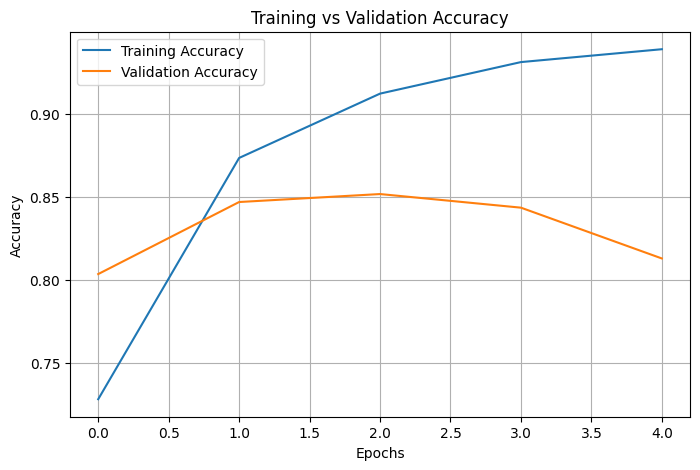

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

### Step 5: Training vs Validation Loss

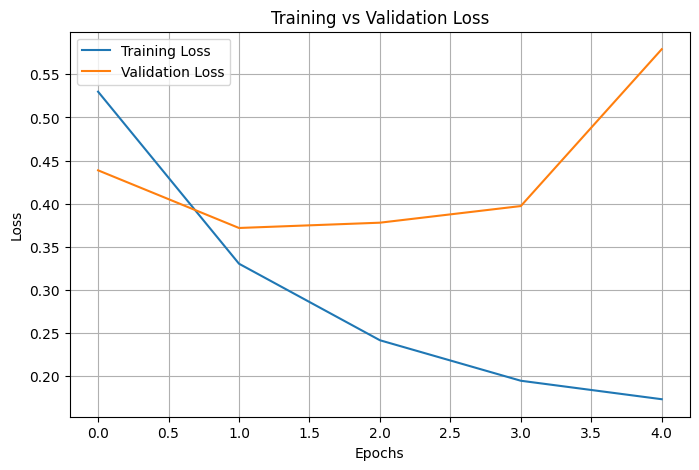

In [51]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### Step 6: Confusion Matrix Visualization

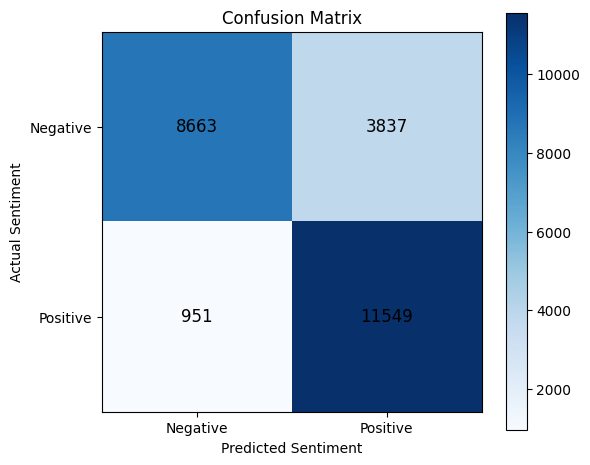

In [52]:
import numpy as np

plt.figure(figsize=(6, 5))

plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion Matrix')
plt.colorbar()

classes = ['Negative', 'Positive']

plt.xticks([0, 1], classes)
plt.yticks([0, 1], classes)

plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, format(cm[i, j], 'd'),
            ha='center',
            va='center',
            color='black',
            fontsize=12
        )

plt.tight_layout()
plt.show()

### Step 7: Actual vs Predicted Sentiment Comparison

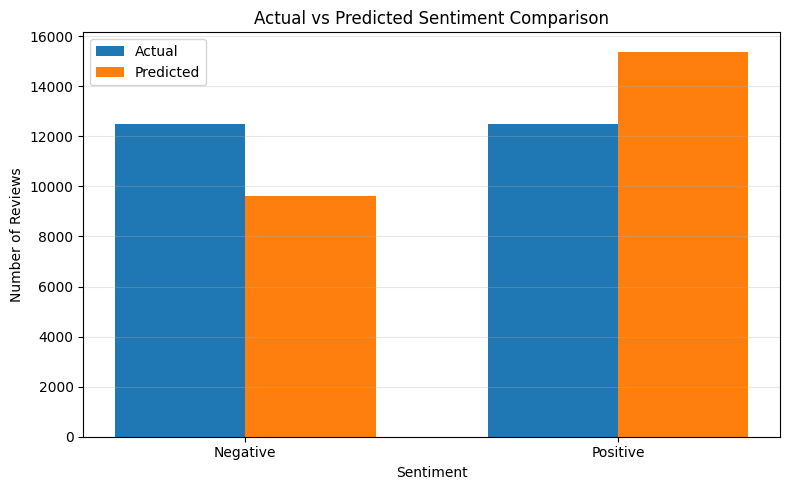

In [53]:
actual_counts = [
    np.sum(y_test == 0),
    np.sum(y_test == 1)
]

predicted_counts = [
    np.sum(y_pred == 0),
    np.sum(y_pred == 1)
]

labels = ['Negative', 'Positive']
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    actual_counts,
    width,
    label='Actual'
)

plt.bar(
    x + width / 2,
    predicted_counts,
    width,
    label='Predicted'
)

plt.title('Actual vs Predicted Sentiment Comparison')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.xticks(x, labels)
plt.legend()
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Task 4 – Conclusion

The LSTM sentiment classification model was evaluated using accuracy, precision, recall, F1 score, and a confusion matrix.

The model achieved 80.85% test accuracy and an F1 score of 0.8283. The visualizations helped analyze training performance, validation performance, classification errors, and actual versus predicted sentiment distributions.

The model demonstrated good performance in identifying positive reviews, although further improvements are needed to reduce false positive predictions and overfitting.

### Task 5 – Performance Analysis

Analyze the performance of the LSTM model.

Discuss:

- Impact of sequence length
- Importance of the embedding layer
- Effect of LSTM memory cells
- Overfitting and possible solutions
- Limitations of the model

## Task 5 – Performance Analysis

### 1. Impact of Sequence Length

Sequence length determines the maximum number of words processed from each review.

In this project, the maximum sequence length is set to 200.

- Padding is used when a review contains fewer than 200 tokens.
- Truncation is used when a review contains more than 200 tokens.
- A shorter sequence length reduces training time and computational cost but may remove important information.
- A longer sequence length preserves more information but requires additional memory and processing time.

**Conclusion:** A sequence length of 200 provides a practical balance between computational efficiency and retaining important review information.

### 2. Importance of the Embedding Layer

The embedding layer converts integer-encoded words into dense numerical vectors.

In this project:
- Vocabulary size: 10,000
- Embedding dimension: 64

Importance:
- Converts words into meaningful numerical representations.
- Learns relationships between words during training.
- Reduces the need for sparse representations.
- Helps the LSTM model learn patterns from review text.

**Conclusion:** The embedding layer plays an important role in transforming text into numerical features suitable for LSTM processing.

### 3. Effect of LSTM Memory Cells

LSTM stands for Long Short-Term Memory.

It is a type of recurrent neural network designed to learn information from sequential data.

Importance:
- Remembers important information from earlier words.
- Uses input, forget, and output gates to control information flow.
- Helps capture relationships between words across a sequence.
- Helps identify sentiment patterns in movie reviews.

**Conclusion:** LSTM memory cells help the model understand word sequences and learn sentiment-related patterns in reviews.

### 4. Overfitting and Possible Solutions

Overfitting occurs when a model performs very well on training data but performs less effectively on unseen data.

In this project:
- Final training accuracy: 93.88%
- Best validation accuracy: 85.16%
- Final validation accuracy: 81.28%
- Test accuracy: 80.85%

The increase in training accuracy and decrease in validation accuracy indicate possible overfitting.

**Possible solutions:**
1. Use Dropout to reduce dependency on specific neurons.
2. Apply Early Stopping to stop training when validation performance stops improving.
3. Use L2 regularization to control model complexity.
4. Experiment with different LSTM units and embedding dimensions.
5. Tune the learning rate and batch size.
6. Collect more diverse training data when possible.

**Conclusion:** Overfitting can be reduced through regularization, early stopping, and hyperparameter tuning.

### 5. Limitations of the Model

- The model is trained using the IMDB movie review dataset, so its performance on other types of customer reviews may differ.
- It uses a fixed sequence length of 200 tokens.
- Words outside the selected vocabulary may be treated as unknown tokens.
- It performs binary classification only: positive or negative.
- It may struggle with sarcasm, mixed sentiments, and complex language.
- It does not explicitly understand real-world context.
- Its performance depends on the quality and diversity of the training data.

### Overall Performance Analysis

The LSTM model achieved 80.85% test accuracy and an F1 score of 0.8283.

It demonstrated good performance in identifying positive reviews, with a recall of 92.39%. However, the model also produced false positive predictions and showed signs of overfitting.

Further improvements using hyperparameter tuning, regularization, and additional training experiments could improve its performance.

In [54]:
import os

os.makedirs("models", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# Save trained LSTM model
model.save("models/lstm_sentiment_model.keras")

print("Model saved successfully!")

Model saved successfully!


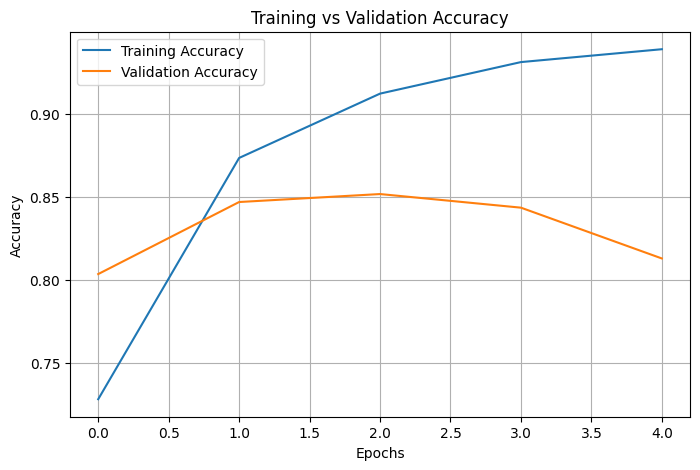

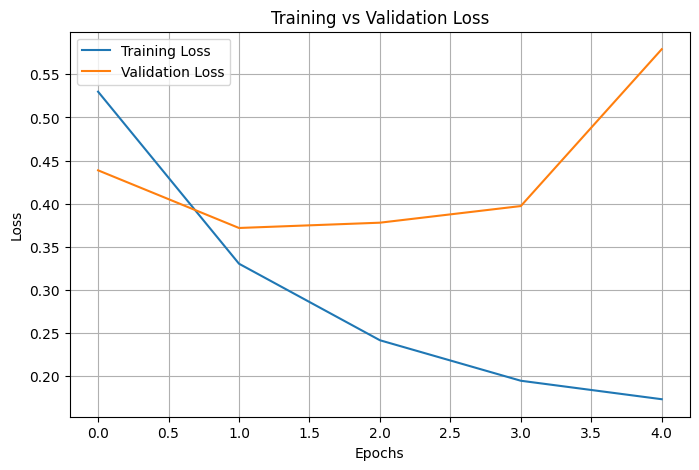

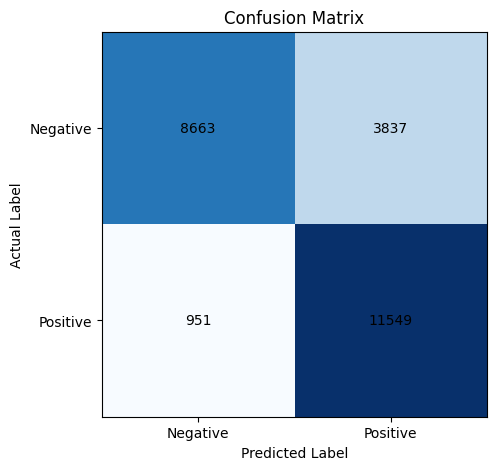

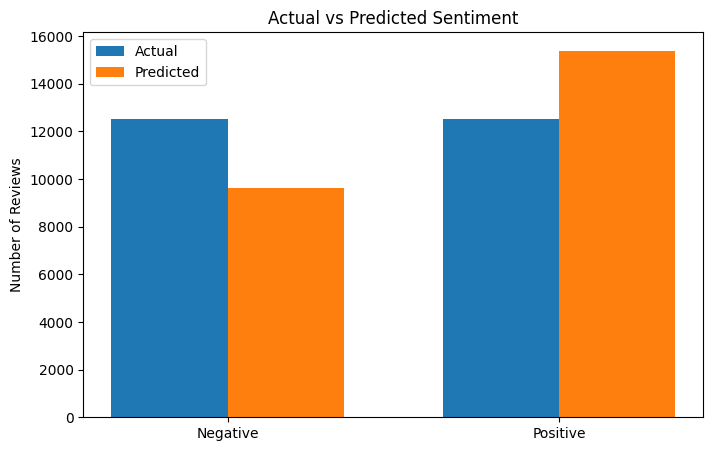

All four graphs saved successfully!


In [55]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Accuracy graph
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.savefig("outputs/accuracy_graph.png", bbox_inches='tight')
plt.show()

# 2. Loss graph
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.savefig("outputs/loss_graph.png", bbox_inches='tight')
plt.show()

# 3. Confusion matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation='nearest', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.yticks([0, 1], ['Negative', 'Positive'])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center')

plt.savefig("outputs/confusion_matrix.png", bbox_inches='tight')
plt.show()

# 4. Actual vs Predicted Sentiment
actual_counts = [np.sum(y_test == 0), np.sum(y_test == 1)]
predicted_counts = [np.sum(y_pred == 0), np.sum(y_pred == 1)]

labels = ['Negative', 'Positive']
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))
plt.bar(x - width/2, actual_counts, width, label='Actual')
plt.bar(x + width/2, predicted_counts, width, label='Predicted')
plt.xticks(x, labels)
plt.title('Actual vs Predicted Sentiment')
plt.ylabel('Number of Reviews')
plt.legend()
plt.savefig("outputs/actual_vs_predicted.png", bbox_inches='tight')
plt.show()

print("All four graphs saved successfully!")

In [56]:
from sklearn.metrics import classification_report

with open("outputs/evaluation_report.txt", "w") as file:
    file.write("CUSTOMER REVIEW SENTIMENT ANALYSIS\n\n")
    file.write(f"Accuracy: {accuracy:.4f}\n")
    file.write(f"Precision: {precision:.4f}\n")
    file.write(f"Recall: {recall:.4f}\n")
    file.write(f"F1 Score: {f1:.4f}\n\n")
    file.write("Classification Report:\n")
    file.write(classification_report(y_test, y_pred))
    file.write("\nConfusion Matrix:\n")
    file.write(str(cm))

print("Evaluation report saved successfully!")

Evaluation report saved successfully!
